# Spoken digit classifier (FSDD)

TODO: 2-3 sentences on what this notebook does and which dataset it uses.


## 0. Setup

Run the notebook from the repository root, so every relative path below works.


In [1]:
from pathlib import Path
import json
import shutil
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

# --- paths -----------------------------------------------------------------
ROOT = Path.cwd()
if ROOT.name == 'notebook':        # notebook opened from inside notebook/
    ROOT = ROOT.parent

DATA_RAW = ROOT / 'data' / 'raw'
DATA_TRAIN = ROOT / 'data' / 'train'
DATA_TEST = ROOT / 'data' / 'test'
MODELS = ROOT / 'models'
for folder in (DATA_RAW, DATA_TRAIN, DATA_TEST, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

# --- settings --------------------------------------------------------------
SEED = 42
SR = 8000          # FSDD clips are 8 kHz mono
DURATION = 1.0     # seconds; clips are 0.3-0.7 s, so we pad or trim to 1 s
N_MELS = 64        # mel bands -> height of the spectrogram image

keras.utils.set_random_seed(SEED)
print('tensorflow', tf.__version__)
print('librosa', librosa.__version__)
print('root', ROOT)

tensorflow 2.21.0
librosa 1.0.1
root C:\Users\Qevin\Downloads\classifier-mlops\spoken-digit-classifier-mlops


## 1. Data acquisition

TODO: name the dataset, its source, its licence, the number of clips, classes
and speakers.


In [2]:
# Free Spoken Digit Dataset: 3000 recordings of the digits 0-9, spoken by 6
# people, CC BY-SA 4.0. Distributed as a zip on GitHub (about 15 MB).
FSDD_URL = 'https://github.com/Jakobovski/free-spoken-digit-dataset/archive/refs/heads/master.zip'
ZIP_PATH = DATA_RAW / 'fsdd.zip'
RECORDINGS_DIR = DATA_RAW / 'free-spoken-digit-dataset-master' / 'recordings'

if not RECORDINGS_DIR.exists():
    if not ZIP_PATH.exists():
        print('downloading', FSDD_URL)
        urllib.request.urlretrieve(FSDD_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(DATA_RAW)

wav_files = sorted(RECORDINGS_DIR.glob('*.wav'))
print(len(wav_files), 'recordings found')
print([w.name for w in wav_files[:3]])

3000 recordings found
['0_george_0.wav', '0_george_1.wav', '0_george_10.wav']


### 1b. Train / test split

TODO: explain why the split is stratified by digit and that the clip files are
copied into `data/train/<digit>/` and `data/test/<digit>/`.


In [3]:
# File names look like 7_jackson_32.wav -> digit, speaker, recording index
rows = []
for wav in wav_files:
    digit, speaker, index = wav.stem.split('_')
    rows.append({'path': wav, 'filename': wav.name,
                 'digit': int(digit), 'speaker': speaker, 'index': int(index)})

clips = pd.DataFrame(rows)
print(clips.shape)
display(clips.head())
print(clips['digit'].value_counts().sort_index().to_dict())
print(clips['speaker'].value_counts().to_dict())

(3000, 5)


,path,filename,digit,speaker,index
0,C:\Users\Qevin\Downloads\classifier-mlops\spok...,0_george_0.wav,0,george,0
1,C:\Users\Qevin\Downloads\classifier-mlops\spok...,0_george_1.wav,0,george,1
2,C:\Users\Qevin\Downloads\classifier-mlops\spok...,0_george_10.wav,0,george,10
3,C:\Users\Qevin\Downloads\classifier-mlops\spok...,0_george_11.wav,0,george,11
4,C:\Users\Qevin\Downloads\classifier-mlops\spok...,0_george_12.wav,0,george,12


{0: 300, 1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300}
{'george': 500, 'jackson': 500, 'lucas': 500, 'nicolas': 500, 'theo': 500, 'yweweler': 500}


In [4]:
train_df, test_df = train_test_split(
    clips, test_size=0.2, stratify=clips['digit'], random_state=SEED)

def copy_split(frame, target_dir):
    '''Copy each clip into target_dir/<digit>/ so the folder layout is the label.'''
    for _, row in frame.iterrows():
        class_dir = target_dir / str(row['digit'])
        class_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(row['path'], class_dir / row['filename'])

copy_split(train_df, DATA_TRAIN)
copy_split(test_df, DATA_TEST)

print('train clips:', len(train_df), '| test clips:', len(test_df))
print('train per digit:', train_df['digit'].value_counts().sort_index().to_dict())
print('test  per digit:', test_df['digit'].value_counts().sort_index().to_dict())

train clips: 2400 | test clips: 600
train per digit: {0: 240, 1: 240, 2: 240, 3: 240, 4: 240, 5: 240, 6: 240, 7: 240, 8: 240, 9: 240}
test  per digit: {0: 60, 1: 60, 2: 60, 3: 60, 4: 60, 5: 60, 6: 60, 7: 60, 8: 60, 9: 60}


## 2. Preprocessing

TODO: explain the audio -> log-mel-spectrogram pipeline: loading at 8 kHz,
padding/trimming to a fixed length, the mel filterbank, the dB conversion and
the 0..1 normalisation. Say why a spectrogram turns sound into an image.


In [5]:
def wav_to_logmel(path):
    '''Turn one clip into a fixed-size, normalised log-mel spectrogram.

    step 1: load as mono at SR Hz
    step 2: zero-pad or trim to exactly DURATION seconds
    step 3: mel-spectrogram with N_MELS bands, then convert to decibels
    step 4: min-max scale to 0..1 so every image has the same range
    '''
    y, _ = librosa.load(path, sr=SR, mono=True)
    target_len = int(SR * DURATION)
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
    else:
        y = y[:target_len]

    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                         n_fft=512, hop_length=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_db = (mel_db - mel_db.min()) / (mel_db.max() - mel_db.min() + 1e-8)
    return mel_db.astype('float32')


def load_split(split_dir):
    '''Read a data/<split>/<digit>/*.wav tree into X (images), y (labels), names.'''
    X, y, names = [], [], []
    for class_dir in sorted(split_dir.iterdir(), key=lambda p: int(p.name)):
        for wav in sorted(class_dir.glob('*.wav')):
            X.append(wav_to_logmel(wav))
            y.append(int(class_dir.name))
            names.append(wav.name)
    X = np.expand_dims(np.array(X), -1)   # (n, mel bands, frames, 1 channel)
    return X, np.array(y), names


X_train, y_train, files_train = load_split(DATA_TRAIN)
X_test, y_test, files_test = load_split(DATA_TEST)
print('X_train', X_train.shape, '| y_train', y_train.shape)
print('X_test ', X_test.shape, '| y_test ', y_test.shape)

X_train (2400, 64, 63, 1) | y_train (2400,)
X_test  (600, 64, 63, 1) | y_test  (600,)


## 3. Look at the data

TODO: describe what the spectrograms and the class balance show.


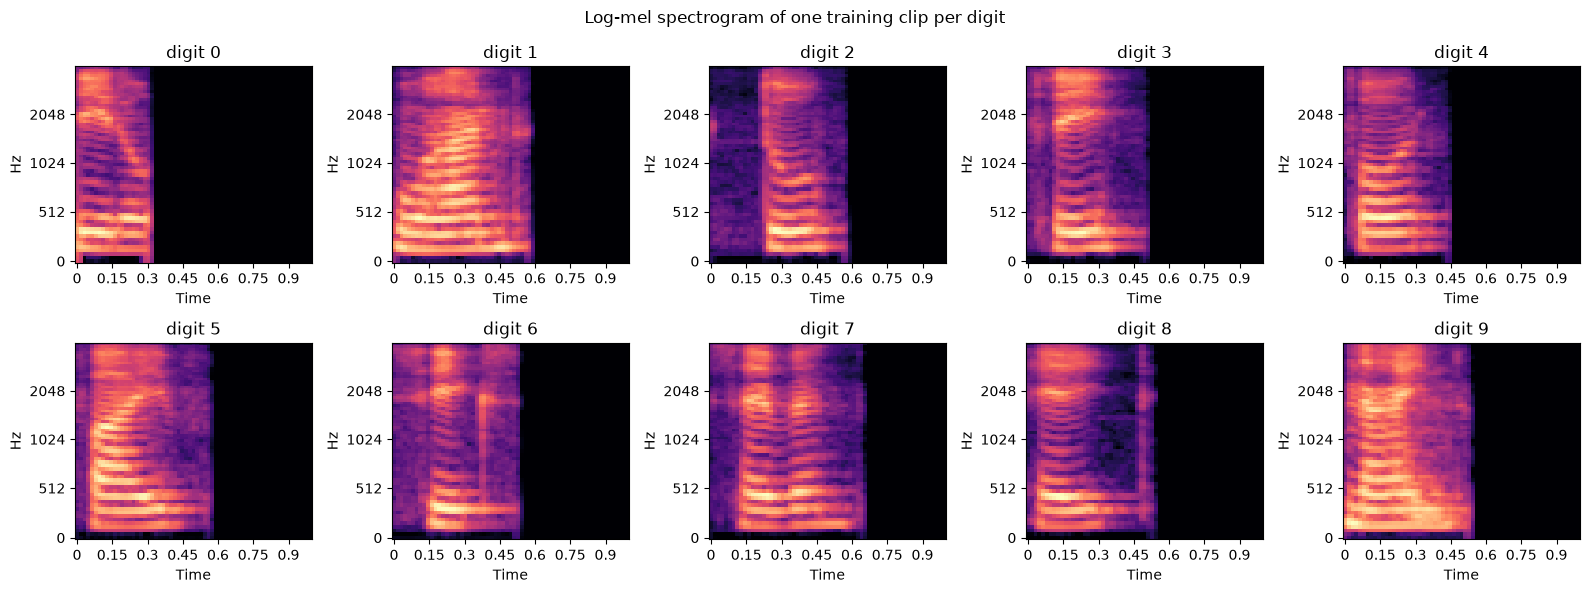

In [6]:
# One example per digit: energy across mel bands over time
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, digit in zip(axes.ravel(), range(10)):
    idx = int(np.where(y_train == digit)[0][0])
    librosa.display.specshow(X_train[idx, :, :, 0], sr=SR, hop_length=128,
                             x_axis='time', y_axis='mel', ax=ax)
    ax.set_title('digit ' + str(digit))
plt.suptitle('Log-mel spectrogram of one training clip per digit')
plt.tight_layout()
plt.show()

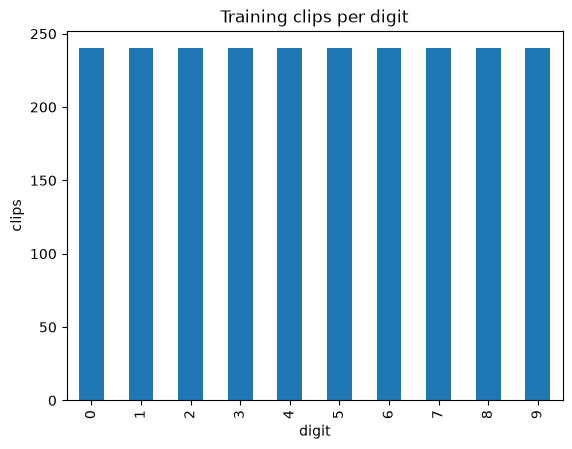

In [7]:
pd.Series(y_train).value_counts().sort_index().plot(
    kind='bar', xlabel='digit', ylabel='clips',
    title='Training clips per digit')
plt.show()

## 4. Model creation

TODO: describe the architecture (three convolutional blocks with dropout, then
a dense head) and the optimisation technique used in the next section.


In [8]:
def build_model(n_classes=10, input_shape=None):
    '''Small CNN for log-mel spectrograms: 3 conv blocks + dense head.'''
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu'),
        layers.Dense(n_classes, activation='softmax'),
    ], name='spoken_digit_cnn')

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


model = build_model(input_shape=X_train.shape[1:])
model.summary()

Model: "spoken_digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 63, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 15, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3584)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3584)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       458,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 515,914 (1.97 MB)

 Trainable params: 515,914 (1.97 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training (optimisation technique: early stopping)

TODO: explain early stopping - it watches the validation loss and stops when it
stops improving (patience), then restores the best weights. Mention the best
model checkpoint and ReduceLROnPlateau.


In [9]:
BEST_MODEL = MODELS / 'spoken_digit_cnn.keras'

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(BEST_MODEL, monitor='val_loss',
                                    save_best_only=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=3, min_lr=1e-5, verbose=1),
]

# Clips are loaded class by class, so shuffle once before carving out a
# validation set - otherwise validation_split would only see the last digits.
rng = np.random.default_rng(SEED)
order = rng.permutation(len(X_train))
X_shuffled, y_shuffled = X_train[order], y_train[order]

history = model.fit(
    X_shuffled, y_shuffled,
    validation_split=0.15,
    epochs=60,
    batch_size=32,
    callbacks=callbacks,
    verbose=2,
)
print('stopped after', len(history.history['loss']), 'epochs')

Epoch 1/60



Epoch 1: val_loss improved from None to 1.87112, saving model to C:\Users\Qevin\Downloads\classifier-mlops\spoken-digit-classifier-mlops\models\spoken_digit_cnn.keras



Epoch 1: finished saving model to C:\Users\Qevin\Downloads\classifier-mlops\spoken-digit-classifier-mlops\models\spoken_digit_cnn.keras


64/64 - 9s - 148ms/step - accuracy: 0.1995 - loss: 2.1733 - val_accuracy: 0.3694 - val_loss: 1.8711 - learning_rate: 0.0010


Epoch 2/60



Epoch 2: val_loss improved from 1.87112 to 0.76268, saving model to C:\Users\Qevin\Downloads\classifier-mlops\spoken-digit-classifier-mlops\models\spoken_digit_cnn.keras


... (118 outputs left out)

64/64 - 6s - 99ms/step - accuracy: 0.9941 - loss: 0.0160 - val_accuracy: 0.9806 - val_loss: 0.0717 - learning_rate: 6.2500e-05


Epoch 34: early stopping


Restoring model weights from the end of the best epoch: 26.


stopped after 34 epochs


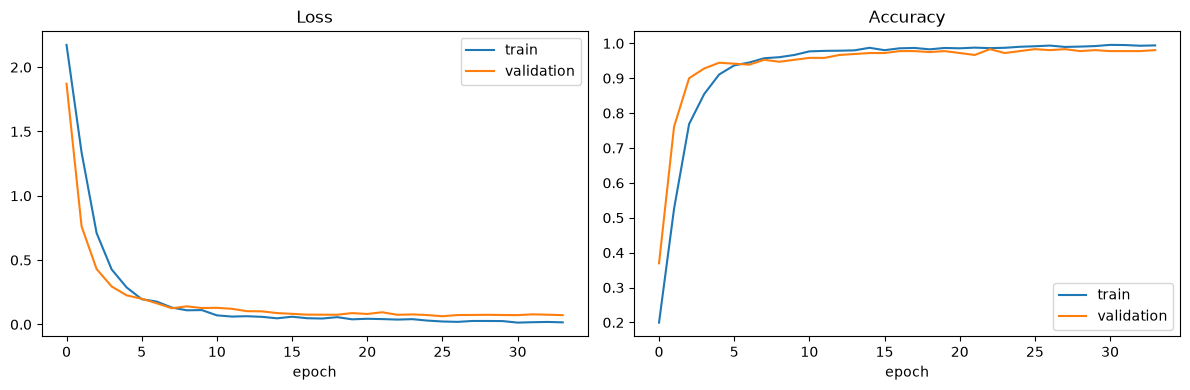

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='validation')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='validation')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Model testing and evaluation

TODO: explain the metrics (accuracy, loss, precision, recall, F1) and why
macro averages matter for a 10-class problem.


In [11]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

metrics = {
    'loss': float(test_loss),
    'accuracy': float(accuracy_score(y_test, y_pred)),
    'precision_macro': float(precision_score(y_test, y_pred, average='macro', zero_division=0)),
    'recall_macro': float(recall_score(y_test, y_pred, average='macro', zero_division=0)),
    'f1_macro': float(f1_score(y_test, y_pred, average='macro', zero_division=0)),
    'precision_weighted': float(precision_score(y_test, y_pred, average='weighted', zero_division=0)),
    'recall_weighted': float(recall_score(y_test, y_pred, average='weighted', zero_division=0)),
    'f1_weighted': float(f1_score(y_test, y_pred, average='weighted', zero_division=0)),
}
print(json.dumps(metrics, indent=2))

{
  "loss": 0.04947739467024803,
  "accuracy": 0.9883333333333333,
  "precision_macro": 0.9886916025524333,
  "recall_macro": 0.9883333333333333,
  "f1_macro": 0.9883562360866518,
  "precision_weighted": 0.9886916025524333,
  "recall_weighted": 0.9883333333333333,
  "f1_weighted": 0.9883562360866517
}


In [12]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        60
           1      1.000     1.000     1.000        60
           2      1.000     0.983     0.992        60
           3      0.938     1.000     0.968        60
           4      1.000     1.000     1.000        60
           5      1.000     1.000     1.000        60
           6      0.983     0.950     0.966        60
           7      0.984     1.000     0.992        60
           8      0.983     0.967     0.975        60
           9      1.000     0.983     0.992        60

    accuracy                          0.988       600
   macro avg      0.989     0.988     0.988       600
weighted avg      0.989     0.988     0.988       600



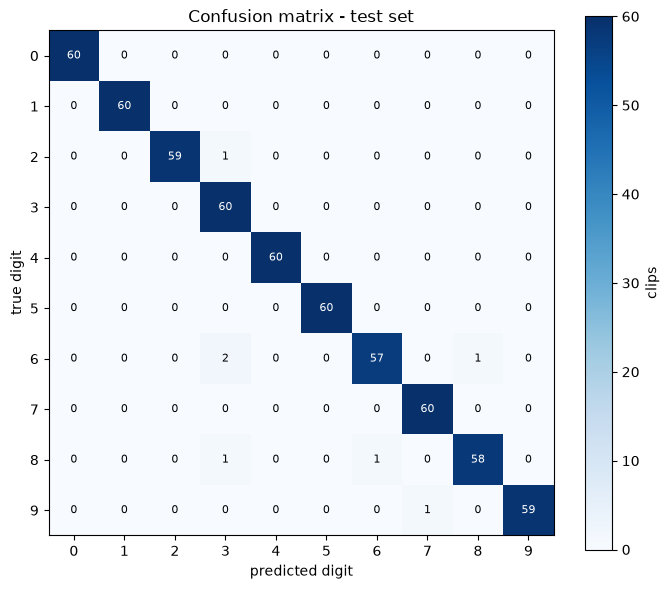

digit 0    1.000
digit 1    1.000
digit 2    0.983
digit 3    1.000
digit 4    1.000
digit 5    1.000
digit 6    0.950
digit 7    1.000
digit 8    0.967
digit 9    0.983


In [13]:
cm = confusion_matrix(y_test, y_pred, labels=range(10))

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, cmap='Blues')
ax.set_xlabel('predicted digit'); ax.set_ylabel('true digit')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
fig.colorbar(image, ax=ax, label='clips')
ax.set_title('Confusion matrix - test set')
plt.tight_layout()
plt.savefig(MODELS / 'confusion_matrix.png', dpi=150)
plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
print(pd.Series(per_class, index=['digit ' + str(d) for d in range(10)]).round(3).to_string())

## 7. Save the model

TODO: note where the model and the metrics are stored and which file the API
will load in step 3.


In [14]:
model.save(MODELS / 'spoken_digit_cnn.h5')      # .h5 as required by the brief
model.save(MODELS / 'spoken_digit_cnn.keras')   # native format, used by the API

metrics['test_clips'] = int(len(y_test))
metrics['epochs_run'] = int(len(history.history['loss']))
metrics['trained_at'] = pd.Timestamp.now(tz='UTC').isoformat()
(MODELS / 'metrics.json').write_text(json.dumps(metrics, indent=2))

print('saved model to', MODELS / 'spoken_digit_cnn.h5')
print(json.dumps(metrics, indent=2))

saved model to C:\Users\Qevin\Downloads\classifier-mlops\spoken-digit-classifier-mlops\models\spoken_digit_cnn.h5
{
  "loss": 0.04947739467024803,
  "accuracy": 0.9883333333333333,
  "precision_macro": 0.9886916025524333,
  "recall_macro": 0.9883333333333333,
  "f1_macro": 0.9883562360866518,
  "precision_weighted": 0.9886916025524333,
  "recall_weighted": 0.9883333333333333,
  "f1_weighted": 0.9883562360866517,
  "test_clips": 600,
  "epochs_run": 34,
  "trained_at": "2026-11-24T10:14:18.988314+00:00"
}


## 8. Interpretation

TODO: write the story of these results - which digits get confused, why, and
what you would try next.
